In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt
import matplotlib.colors as mplcolors
import matplotlib.ticker as ptick
import matplotlib.patches as patches
import matplotlib.patheffects as pe
from MyPlotRecipe.SharedX import ShareXaxis
from MyPlotRecipe.UniversalColor import UniversalColor
from MyPlotRecipe.legend_shadow import legend_shadow

import time
import spiceypy as spice
import JupiterMag as jm
from CSField import CSField

UC = UniversalColor()
UC.set_palette()

F = ShareXaxis()
F.fontsize = 23
F.fontname = 'Liberation Sans Narrow'
F.set_default()

jm.Internal.Config(Model='jrm33', Degree=3, CartesianIn=True,
                   CartesianOut=True)
jm.Con2020.Config(equation_type='integral')

spice.furnsh(
    '/Users/shin/Documents/Research/Jupiter/Codes/HST/kernel/cassMetaK.txt')
radii = spice.bodvrd("JUPITER", "RADII", 3)[1]
RJ_km = radii[0]
c = radii[2]
f = (RJ_km - c) / RJ_km

Importing Library
done


In [2]:
# ===========================================================
# CONSTANTS
# ===========================================================
MU0 = 4*np.pi*1E-7       # 真空中の透磁率 [H m-1]
AMU2KG = 1.66E-27        # [kg]
RJ = 71492.0E+3          # JUPITER RADIUS [m]


# ===========================================================
# CONFIGURE CSFIELD
# ===========================================================
csfield = CSField()
csfield.config(
    I_rho0=0.0,  # 8.3795
    i_phi0=4.91719E-5,
    b1=0.0,
)

In [3]:
# ===========================================================
# FIELD LINE TRACE (DAWN)
# ===========================================================
r_cs = np.array([5.9, 9.4, 15.0, 26.0])*RJ  # [m]
theta_cs = np.radians(89.99)  # Colatitude [rad]
phi_cs = 0.0  # [rad]

x_cs0 = r_cs*np.sin(theta_cs)*np.cos(phi_cs)
y_cs0 = r_cs*np.sin(theta_cs)*np.sin(phi_cs)
z_cs0 = r_cs*np.cos(theta_cs)

x0, y0, z0, = csfield._cs_2_sys3(x_cs0, y_cs0, z_cs0,
                                 np.sqrt(x_cs0**2+y_cs0**2), phi_cs)


Niter = 80000

ds0 = 1000000.0   # [m]
p = 1.2

result_arr0 = np.zeros((r_cs.size*2, 3, int(Niter/10)))

# 北半球
ns = -1     # -1: north; 1: south
start = time.time()
for j in range(x0.size):
    k = 0
    x, y, z = x0[j], y0[j], z0[j]
    for i in range(Niter):
        Bx0, By0, Bz0 = jm.Internal.Field(x/RJ, y/RJ, z/RJ)       # [nT]
        Bx1, By1, Bz1 = csfield.magnetic_field(x/RJ, y/RJ, z/RJ,
                                               MLT=0.0)  # [T]
        Bx = (Bx0*1E-9)+Bx1     # [T]
        By = (By0*1E-9)+By1     # [T]
        Bz = (Bz0*1E-9)+Bz1     # [T]
        B0 = math.sqrt(Bx[0]**2+By[0]**2+Bz[0]**2)      # [T]

        ds = ds0/(np.log10(B0*1E+9))**p      # [m]

        # 座標更新 (x, y, z)
        x += (ds*Bx[0]/B0)*ns
        y += (ds*By[0]/B0)*ns
        z += (ds*Bz[0]/B0)*ns

        # if i % 200 == 0:
        #     print('ds [km]:', ds/1000.0)

        # 座標更新 (r, theta, phi)
        rs = math.sqrt(x**2 + y**2 + z**2)
        theta = math.acos(z/rs)
        phi = math.atan2(y, x)

        if i % 10 == 0:
            x_cs, y_cs, z_cs = csfield._sys3_2_cs(x, y, z)
            result_arr0[j, 0, k] = x_cs/RJ
            result_arr0[j, 1, k] = y_cs/RJ
            result_arr0[j, 2, k] = z_cs/RJ
            # result_arr0[j, 0, k] = x/RJ
            # result_arr0[j, 1, k] = y/RJ
            # result_arr0[j, 2, k] = z/RJ
            k += 1

        # 終了条件
        if rs < (1.0*RJ+2000.0E+3):
            # ds = 5000.0     # [m]
            lon_gr, lat_gr, alt_gr = spice.recpgr('JUPITER',
                                                  np.array([x/1000.0,
                                                            y/1000.0,
                                                            z/1000.0]),
                                                  RJ_km,
                                                  f)
            if abs(alt_gr-1.0)*1000.0 <= 0.5*ds:
                print('End altitude [km]:', round(alt_gr, 2))
                break


# 南半球
ns = 1     # -1: north; 1: south
start = time.time()
for j in range(x0.size):
    k = 0
    x, y, z = x0[j], y0[j], z0[j]
    for i in range(Niter):
        Bx0, By0, Bz0 = jm.Internal.Field(x/RJ, y/RJ, z/RJ)       # [nT]
        Bx1, By1, Bz1 = csfield.magnetic_field(x/RJ, y/RJ, z/RJ,
                                               MLT=0.0)  # [T]
        Bx = (Bx0*1E-9)+Bx1     # [T]
        By = (By0*1E-9)+By1     # [T]
        Bz = (Bz0*1E-9)+Bz1     # [T]
        B0 = math.sqrt(Bx[0]**2+By[0]**2+Bz[0]**2)      # [T]

        ds = ds0/(np.log10(B0*1E+9))**p      # [m]

        # 座標更新 (x, y, z)
        x += (ds*Bx[0]/B0)*ns
        y += (ds*By[0]/B0)*ns
        z += (ds*Bz[0]/B0)*ns

        # if i % 200 == 0:
        #     print('ds [km]:', ds/1000.0)

        # 座標更新 (r, theta, phi)
        rs = math.sqrt(x**2 + y**2 + z**2)
        theta = math.acos(z/rs)
        phi = math.atan2(y, x)

        if i % 10 == 0:
            x_cs, y_cs, z_cs = csfield._sys3_2_cs(x, y, z)
            result_arr0[j+x0.size, 0, k] = x_cs/RJ
            result_arr0[j+x0.size, 1, k] = y_cs/RJ
            result_arr0[j+x0.size, 2, k] = z_cs/RJ
            # result_arr0[j+x0.size, 0, k] = x/RJ
            # result_arr0[j+x0.size, 1, k] = y/RJ
            # esult_arr0[j+x0.size, 2, k] = z/RJ
            k += 1

        # 終了条件
        if rs < (1.0*RJ+2000.0E+3):
            # ds = 5000.0     # [m]
            lon_gr, lat_gr, alt_gr = spice.recpgr('JUPITER',
                                                  np.array([x/1000.0,
                                                            y/1000.0,
                                                            z/1000.0]),
                                                  RJ_km,
                                                  f)
            if abs(alt_gr-1.0)*1000.0 <= 0.5*ds:
                print('End altitude [km]:', round(alt_gr, 2))
                break

End altitude [km]: 30.13
End altitude [km]: 43.84
End altitude [km]: -5.37
End altitude [km]: -39.56
End altitude [km]: -13.61
End altitude [km]: 17.18
End altitude [km]: 50.72
End altitude [km]: 50.84


In [4]:
# ===========================================================
# FIELD LINE TRACE (JRM33 ONLY)
# ===========================================================
r_cs = np.array([5.9, 9.4, 15.0, 26.0])*RJ  # [m]
theta_cs = np.radians(89.99)  # Colatitude [rad]
phi_cs = 0.0  # [rad]

x_cs0 = r_cs*np.sin(theta_cs)*np.cos(phi_cs)
y_cs0 = r_cs*np.sin(theta_cs)*np.sin(phi_cs)
z_cs0 = r_cs*np.cos(theta_cs)

x0, y0, z0, = csfield._cs_2_sys3(x_cs0, y_cs0, z_cs0,
                                 np.sqrt(x_cs0**2+y_cs0**2), phi_cs)


Niter = 80000

ds0 = 1000000.0   # [m]
p = 1.2

result_arr1 = np.zeros((r_cs.size*2, 3, int(Niter/10)))

# 北半球
ns = -1     # -1: north; 1: south
start = time.time()
for j in range(x0.size):
    k = 0
    x, y, z = x0[j], y0[j], z0[j]
    for i in range(Niter):
        Bx0, By0, Bz0 = jm.Internal.Field(x/RJ, y/RJ, z/RJ)       # [nT]
        Bx1, By1, Bz1 = 0.0, 0.0, 0.0
        Bx = (Bx0*1E-9)+Bx1     # [T]
        By = (By0*1E-9)+By1     # [T]
        Bz = (Bz0*1E-9)+Bz1     # [T]
        B0 = math.sqrt(Bx[0]**2+By[0]**2+Bz[0]**2)      # [T]

        ds = ds0/(np.log10(B0*1E+9))**p      # [m]

        # 座標更新 (x, y, z)
        x += (ds*Bx[0]/B0)*ns
        y += (ds*By[0]/B0)*ns
        z += (ds*Bz[0]/B0)*ns

        # if i % 200 == 0:
        #     print('ds [km]:', ds/1000.0)

        # 座標更新 (r, theta, phi)
        rs = math.sqrt(x**2 + y**2 + z**2)
        theta = math.acos(z/rs)
        phi = math.atan2(y, x)

        if i % 10 == 0:
            x_cs, y_cs, z_cs = csfield._sys3_2_cs(x, y, z)
            result_arr1[j, 0, k] = x_cs/RJ
            result_arr1[j, 1, k] = y_cs/RJ
            result_arr1[j, 2, k] = z_cs/RJ
            # result_arr0[j, 0, k] = x/RJ
            # result_arr0[j, 1, k] = y/RJ
            # result_arr0[j, 2, k] = z/RJ
            k += 1

        # 終了条件
        if rs < (1.0*RJ+2000.0E+3):
            # ds = 5000.0     # [m]
            lon_gr, lat_gr, alt_gr = spice.recpgr('JUPITER',
                                                  np.array([x/1000.0,
                                                            y/1000.0,
                                                            z/1000.0]),
                                                  RJ_km,
                                                  f)
            if abs(alt_gr-1.0)*1000.0 <= 0.5*ds:
                print('End altitude [km]:', round(alt_gr, 2))
                break


# 南半球
ns = 1     # -1: north; 1: south
start = time.time()
for j in range(x0.size):
    k = 0
    x, y, z = x0[j], y0[j], z0[j]
    for i in range(Niter):
        Bx0, By0, Bz0 = jm.Internal.Field(x/RJ, y/RJ, z/RJ)       # [nT]
        Bx1, By1, Bz1 = 0.0, 0.0, 0.0
        Bx = (Bx0*1E-9)+Bx1     # [T]
        By = (By0*1E-9)+By1     # [T]
        Bz = (Bz0*1E-9)+Bz1     # [T]
        B0 = math.sqrt(Bx[0]**2+By[0]**2+Bz[0]**2)      # [T]

        ds = ds0/(np.log10(B0*1E+9))**p      # [m]

        # 座標更新 (x, y, z)
        x += (ds*Bx[0]/B0)*ns
        y += (ds*By[0]/B0)*ns
        z += (ds*Bz[0]/B0)*ns

        # if i % 200 == 0:
        #     print('ds [km]:', ds/1000.0)

        # 座標更新 (r, theta, phi)
        rs = math.sqrt(x**2 + y**2 + z**2)
        theta = math.acos(z/rs)
        phi = math.atan2(y, x)

        if i % 10 == 0:
            x_cs, y_cs, z_cs = csfield._sys3_2_cs(x, y, z)
            result_arr1[j+x0.size, 0, k] = x_cs/RJ
            result_arr1[j+x0.size, 1, k] = y_cs/RJ
            result_arr1[j+x0.size, 2, k] = z_cs/RJ
            # result_arr0[j+x0.size, 0, k] = x/RJ
            # result_arr0[j+x0.size, 1, k] = y/RJ
            # esult_arr0[j+x0.size, 2, k] = z/RJ
            k += 1

        # 終了条件
        if rs < (1.0*RJ+2000.0E+3):
            # ds = 5000.0     # [m]
            lon_gr, lat_gr, alt_gr = spice.recpgr('JUPITER',
                                                  np.array([x/1000.0,
                                                            y/1000.0,
                                                            z/1000.0]),
                                                  RJ_km,
                                                  f)
            if abs(alt_gr-1.0)*1000.0 <= 0.5*ds:
                print('End altitude [km]:', round(alt_gr, 2))
                break

End altitude [km]: -15.96
End altitude [km]: -41.09
End altitude [km]: 10.09
End altitude [km]: 0.64
End altitude [km]: 0.19
End altitude [km]: -37.64
End altitude [km]: -16.28
End altitude [km]: -3.7


In [5]:
PJ_num = 24
dir = 'data/FGM/PJ'+str(PJ_num).zfill(2)+'/'
time_arr = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_time.txt')
Bx_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_Bx.txt')
By_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_By.txt')
Bz_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_Bz.txt')
rx_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_rx.txt')
ry_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_ry.txt')
rz_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_rz.txt')
JunoMLT = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_JunoMLT.txt')

rx_pc *= 1/71492.0  # [RJ]
ry_pc *= 1/71492.0  # [RJ]
rz_pc *= 1/71492.0  # [RJ]

x_cs, y_cs, z_cs = csfield._sys3_2_cs(rx_pc, ry_pc, rz_pc)
phi_cs = np.arctan2(y_cs, x_cs)
rho_cs = np.sqrt(x_cs**2 + y_cs**2)

print(z_cs.shape, rho_cs.shape)

(4276,) (4276,)


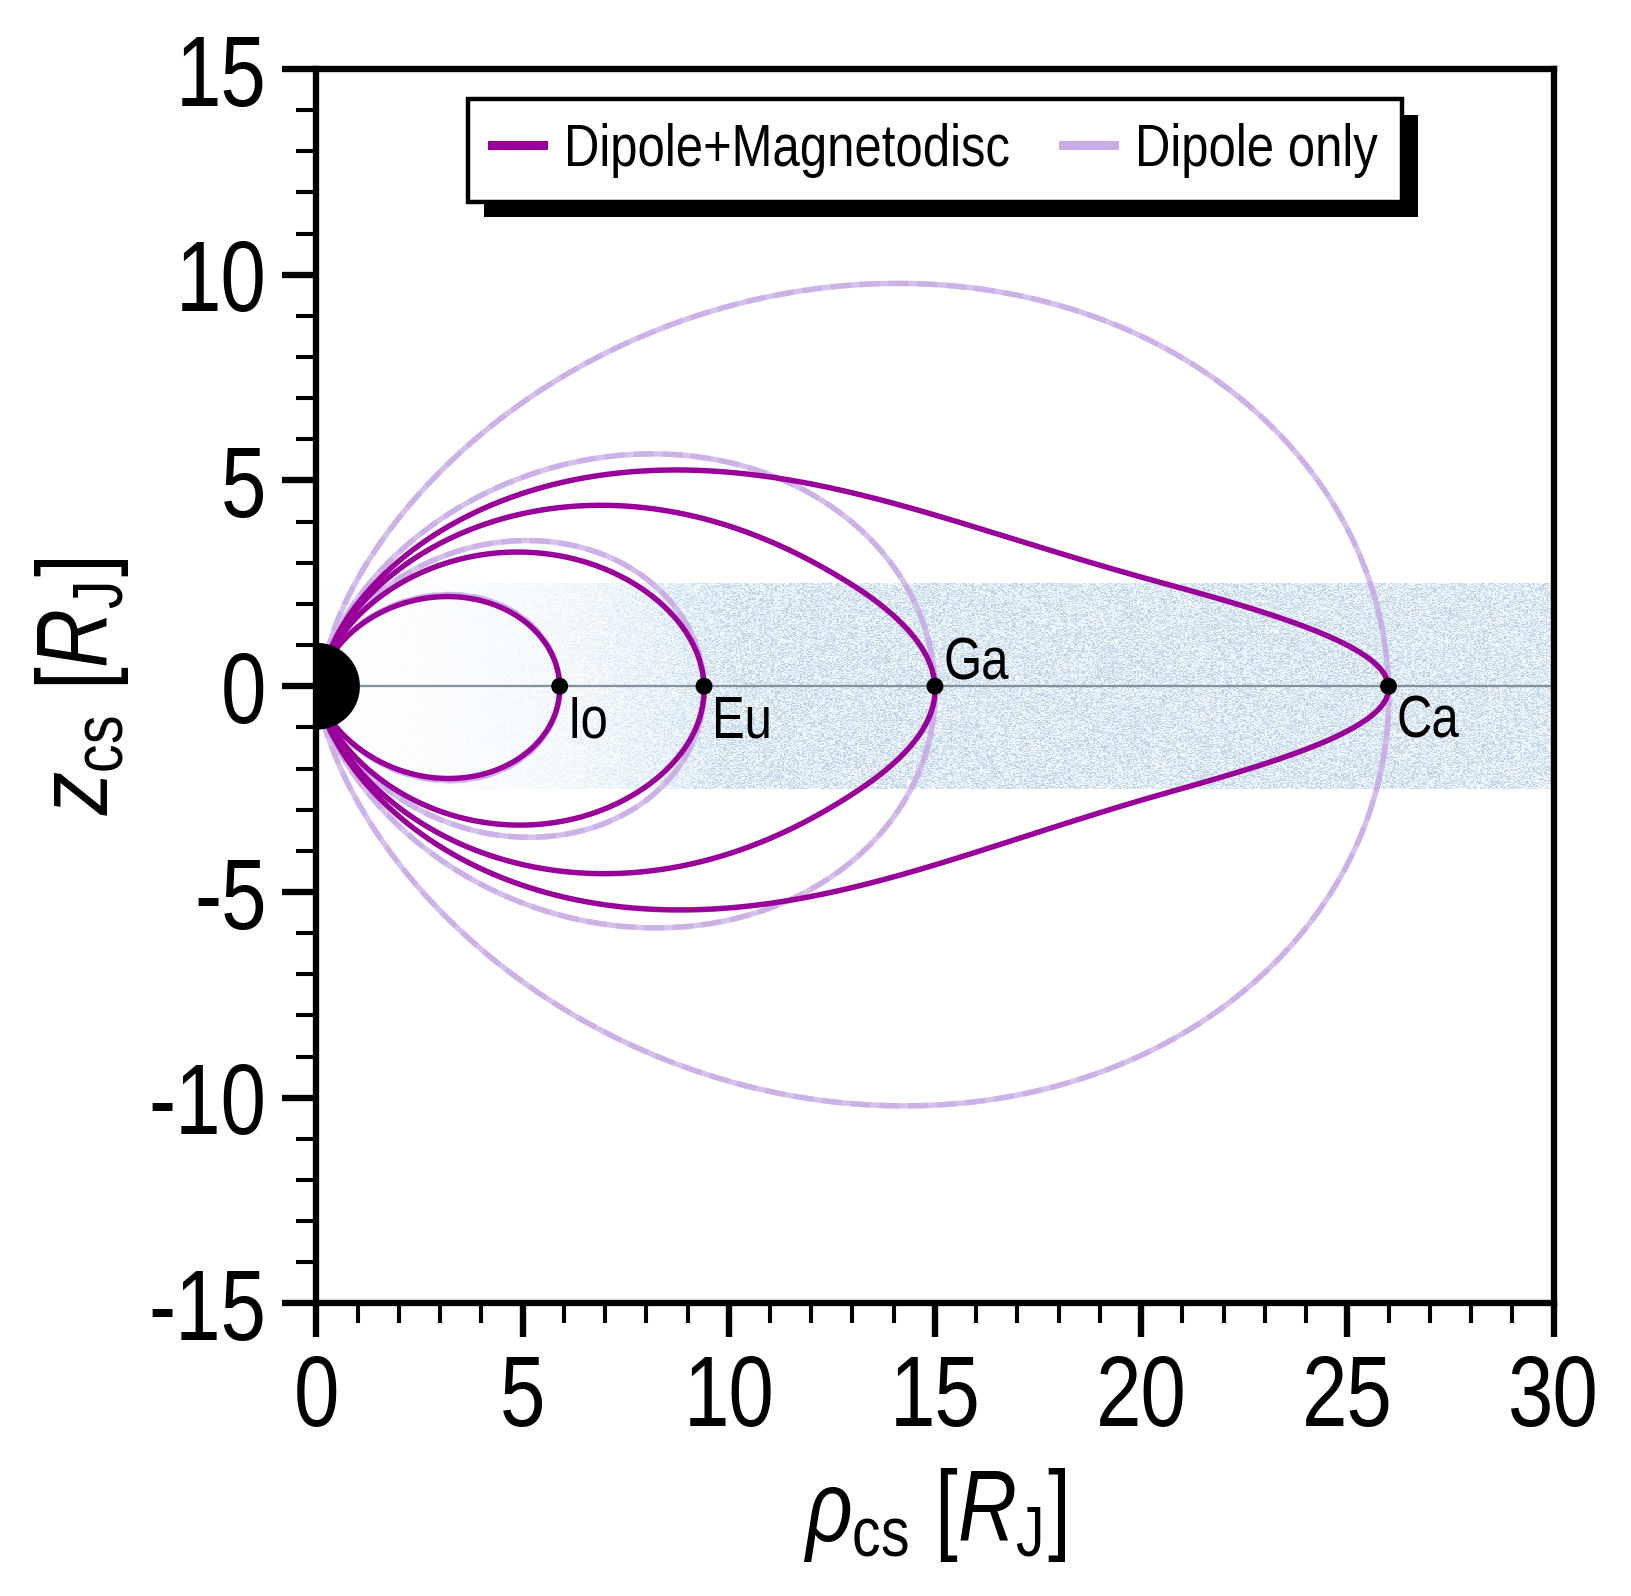

In [6]:
F = ShareXaxis()
F.fontsize = 22
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=1, figsize=(5.2, 5.), dpi='XL')
F.initialize()

F.ax.set_aspect('equal')

F.set_xaxis(label=r'$\rho_{\rm cs}$ [$R_{\rm J}$]',
            min=0.0, max=30.0,
            ticks=np.arange(0, 30+1, 5),
            ticklabels=np.arange(0, 30+1, 5),
            minor_num=5)
F.set_yaxis(ax_idx=0,
            label=r'$z_{\rm cs}$ [$R_{\rm J}$]',
            min=-15.0, max=15.0,
            ticks=np.arange(-15, 15+1, 5),
            ticklabels=np.arange(-15, 15+1, 5, dtype=int),
            minor_num=5,)

for i in range(result_arr0.shape[0]):
    rho_cs_fl = np.sqrt(result_arr0[i, 0, :]**2+result_arr0[i, 1, :]**2)
    F.ax.plot(rho_cs_fl, result_arr0[i, 2, :],
              linewidth=1.2, color=UC.purple, zorder=2.0)
for i in range(result_arr1.shape[0]):
    rho_cs_fl = np.sqrt(result_arr1[i, 0, :]**2+result_arr1[i, 1, :]**2)
    F.ax.plot(rho_cs_fl, result_arr1[i, 2, :],
              linewidth=1.2, color=UC.lightpurple, alpha=0.75, zorder=1.0,)
    F.ax.plot(rho_cs_fl, result_arr1[i, 2, :],
              linewidth=1.2, color=UC.lightpurple, alpha=0.75, linestyle='--', zorder=1.0,)
F.ax.axhline(y=0.0, color=UC.gray, linewidth=0.5, zorder=0.9)

"""# Juno trajectory
F.ax.plot(rho_cs, z_cs, linewidth=0.75, color='Gray')
F.ax.text(5.0, -13.0, 'PJ24 trajectory',
          color='Gray',
          fontsize=F.fontsize*0.55,
          verticalalignment='top',
          horizontalalignment='left',)"""

# z_cs current sheet shade
rng = np.random.default_rng(40)
noise = rng.random((500, 1500))
weight = np.clip(np.linspace(0.0, 50.0, noise.shape[1])/10.0, 0.0, 1.0)**2.0
noise *= weight[None, :]
im = F.ax.imshow(
    noise,
    extent=[0.0, 50.0, -2.5, 2.5],
    origin="lower",
    cmap="Blues",
    alpha=0.25,
    interpolation="nearest",
    aspect="auto",
)

# Jupiter
F.ax.add_patch(plt.Circle((0, 0), 1.0, color='k',
                          zorder=2, fill=True, clip_on=True))

# Galilean moons
radii = [5.9, 9.4, 15.0, 26.0]
name = ['Io', 'Eu', 'Ga', 'Ca']
labelz = [-0.2, -0.2, 1.2, -0.2]
for i in range(len(radii)):
    F.ax.add_patch(plt.Circle((radii[i], 0), 0.15, color='k',
                              zorder=2, fill=True, clip_on=True))
    F.ax.text(radii[i]+0.2, labelz[i], name[i],
              color='k',
              fontsize=F.fontsize*0.6,
              verticalalignment='top',
              horizontalalignment='left',)

# Dummy
F.ax.plot([-99, -98], [-99, -98], color=UC.purple,
          linewidth=2.0, label='Dipole+Magnetodisc')
F.ax.plot([-99, -98], [-99, -98], color=UC.lightpurple,
          linewidth=2.0, label='Dipole only')

legend = F.legend(ax_idx=0,
                  ncol=2, markerscale=1.0,
                  loc='upper center',
                  handlelength=0.85,
                  textcolor=False,
                  fontsize_scale=0.6,
                  handletextpad=0.35)
legend_shadow(legend=legend, fig=F.fig, ax=F.ax, d=0.7)

plt.savefig('img/compare_a0_a1_b3_36rj/Galilean_fieldlines.pdf',
            bbox_inches='tight')